In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "db" / "retail.db"
REPORTS_DIR = PROJECT_ROOT / "reports"

conn = sqlite3.connect(DB_PATH)

sales = pd.read_sql("""
SELECT oi.order_id, oi.product_id, oi.quantity, oi.unit_price, oi.discount_pct,
       oi.is_returned, oi.line_revenue,
       o.order_ts, o.customer_id, o.store_id, o.channel,
       p.category, p.unit_cost,
       s.store_name, s.region, s.store_type
FROM clean_order_items AS oi
JOIN clean_orders   AS o ON o.order_id   = oi.order_id
JOIN clean_products AS p ON p.product_id = oi.product_id
JOIN clean_stores   AS s ON s.store_id   = o.store_id
""", conn, parse_dates=["order_ts"])

sales["is_returned"] = sales["is_returned"].astype(bool)

print(sales.shape)
sales.head(3)

(204170, 16)


,order_id,product_id,quantity,unit_price,discount_pct,is_returned,line_revenue,order_ts,customer_id,store_id,channel,category,unit_cost,store_name,region,store_type
0,O0000001,P0249,1,1640.0,0.0,False,1640.0,2024-01-02 16:34:00,C01849,S004,Online,Home & Kitchen,1122.95,Mumbai Standard,West,Standard
1,O0000002,P0249,1,1640.0,15.0,False,1394.0,2024-01-03 11:55:00,C02181,S002,In-store,Home & Kitchen,1122.95,Hyderabad Standard,South,Standard
2,O0000002,P0046,2,140.0,10.0,False,252.0,2024-01-03 11:55:00,C02181,S002,In-store,Grocery,93.34,Hyderabad Standard,South,Standard


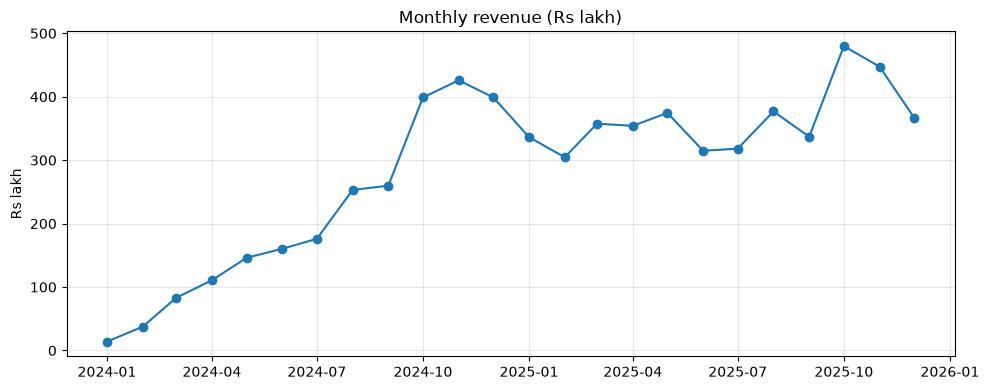

In [2]:
monthly_revenue = sales.set_index("order_ts")["line_revenue"].resample("MS").sum() / 1e5

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_revenue.index, monthly_revenue.values, marker="o")
ax.set_title("Monthly revenue (Rs lakh)")
ax.set_ylabel("Rs lakh")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "monthly_revenue.png", dpi=100)
plt.show()

In [4]:
active_customers = sales.set_index("order_ts")["customer_id"].resample("MS").nunique()
active_customers

order_ts
2024-01-01      89
2024-02-01     218
2024-03-01     416
2024-04-01     571
2024-05-01     738
2024-06-01     860
2024-07-01     966
2024-08-01    1184
2024-09-01    1268
2024-10-01    1574
2024-11-01    1671
2024-12-01    1695
2025-01-01    1576
2025-02-01    1562
2025-03-01    1640
2025-04-01    1670
2025-05-01    1680
2025-06-01    1588
2025-07-01    1556
2025-08-01    1561
2025-09-01    1485
2025-10-01    1627
2025-11-01    1513
2025-12-01    1376
Freq: MS, Name: customer_id, dtype: int64

In [5]:
monthly_table = pd.DataFrame({
    "month": monthly_revenue.index.strftime("%Y-%m"),
    "revenue_lakh": monthly_revenue.values.round(2),
    "active_customers": active_customers.values,
})

monthly_table.to_sql("eda_monthly_revenue", conn, if_exists="replace", index=False)
monthly_table.to_csv(REPORTS_DIR / "eda_monthly_revenue.csv", index=False)

pd.read_sql("SELECT * FROM eda_monthly_revenue", conn)

,month,revenue_lakh,active_customers
0,2024-01,13.94,89
1,2024-02,37.41,218
2,2024-03,83.00,416
3,2024-04,110.66,571
4,2024-05,145.99,738
5,2024-06,160.32,860
6,2024-07,176.02,966
7,2024-08,253.04,1184
8,2024-09,259.82,1268
9,2024-10,398.84,1574


In [12]:
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

sales_2025 = sales[sales["order_ts"].dt.year == 2025]

daily = sales_2025.groupby(sales_2025["order_ts"].dt.date)["line_revenue"].sum()
daily.index = pd.to_datetime(daily.index)

weekday_avg = daily.groupby(daily.index.day_of_week).mean() / 1e5

weekday_table = pd.DataFrame({
    "day_of_week": DAY_NAMES,
    "avg_daily_revenue_lakh": weekday_avg.values.round(2),
})
avg = weekday_table["avg_daily_revenue_lakh"].mean()
weekday_table["vs_average_pct"] = (100 * (weekday_table["avg_daily_revenue_lakh"] / avg - 1)).round(1)

weekday_table

,day_of_week,avg_daily_revenue_lakh,vs_average_pct
0,Mon,9.93,-17.1
1,Tue,10.42,-13.0
2,Wed,10.38,-13.3
3,Thu,11.00,-8.1
4,Fri,12.44,3.9
5,Sat,15.33,28.0
6,Sun,14.31,19.5


In [7]:
monthly_2025 = sales_2025.groupby(sales_2025["order_ts"].dt.month)["line_revenue"].sum() / 1e5

season_table = pd.DataFrame({
    "month": range(1, 13),
    "revenue_lakh": monthly_2025.values.round(2),
})
avg = season_table["revenue_lakh"].mean()
season_table["vs_average_pct"] = (100 * (season_table["revenue_lakh"] / avg - 1)).round(1)

season_table

,month,revenue_lakh,vs_average_pct
0,1,336.31,-7.6
1,2,304.63,-16.3
2,3,357.56,-1.8
3,4,354.14,-2.7
4,5,374.54,2.9
5,6,314.85,-13.5
6,7,318.17,-12.6
7,8,376.83,3.5
8,9,336.97,-7.4
9,10,479.85,31.8


In [8]:
weekday_table.to_sql("eda_weekday_pattern", conn, if_exists="replace", index=False)
weekday_table.to_csv(REPORTS_DIR / "eda_weekday_pattern.csv", index=False)

season_table.to_sql("eda_monthly_seasonality", conn, if_exists="replace", index=False)
season_table.to_csv(REPORTS_DIR / "eda_monthly_seasonality.csv", index=False)

print("Saved eda_weekday_pattern and eda_monthly_seasonality")

Saved eda_weekday_pattern and eda_monthly_seasonality


In [9]:
store = (sales.groupby(["store_id", "store_name", "region", "store_type"])
         .agg(revenue=("line_revenue", "sum"),
              orders=("order_id", "nunique"),
              customers=("customer_id", "nunique"))
         .reset_index())

store["revenue_lakh"] = (store["revenue"] / 1e5).round(1)
store["avg_order_value"] = (store["revenue"] / store["orders"]).round(0)
store = store.drop(columns="revenue").sort_values("revenue_lakh", ascending=False)

store

,store_id,store_name,region,store_type,orders,customers,revenue_lakh,avg_order_value
8,S009,Lucknow Flagship,North,Flagship,12373,1316,1033.5,8353.0
4,S005,Pune Flagship,West,Flagship,11077,1294,936.1,8451.0
3,S004,Mumbai Standard,West,Standard,8020,1100,669.5,8348.0
10,S011,Bhubaneswar Standard,East,Standard,7165,1080,594.8,8302.0
9,S010,Kolkata Standard,East,Standard,7072,1075,579.5,8194.0
1,S002,Hyderabad Standard,South,Standard,6766,1064,576.4,8519.0
6,S007,Delhi Express,North,Express,5464,990,458.2,8385.0
11,S012,Guwahati Express,East,Express,4976,966,420.3,8447.0
7,S008,Jaipur Express,North,Express,4989,972,407.2,8163.0
2,S003,Chennai Express,South,Express,4765,990,395.7,8305.0


In [10]:
region = (store.groupby("region")[["revenue_lakh", "orders"]].sum()
          .sort_values("revenue_lakh", ascending=False).reset_index())

store_type = store.groupby("store_type").agg(stores=("store_id", "count"),
                                              revenue_lakh=("revenue_lakh", "sum")).reset_index()
store_type["revenue_per_store_lakh"] = (store_type["revenue_lakh"] / store_type["stores"]).round(1)

print(region)
print()
print(store_type)

  region  revenue_lakh  orders
0   West        1978.1   23567
1  North        1898.9   22826
2   East        1594.6   19213
3  South        1360.8   16148

  store_type  stores  revenue_lakh  revenue_per_store_lakh
0    Express       6        2442.6                   407.1
1   Flagship       2        1969.6                   984.8
2   Standard       4        2420.2                   605.0


In [11]:
store.to_sql("eda_store_performance", conn, if_exists="replace", index=False)
store.to_csv(REPORTS_DIR / "eda_store_performance.csv", index=False)

region.to_sql("eda_region_performance", conn, if_exists="replace", index=False)
store_type.to_sql("eda_store_type_performance", conn, if_exists="replace", index=False)

print("Saved store, region and store-type tables")

Saved store, region and store-type tables


In [13]:
sales["line_cost"] = sales["quantity"] * sales["unit_cost"]
sales["line_profit"] = sales["line_revenue"] - sales["line_cost"]

category = (sales.groupby("category")
            .agg(revenue=("line_revenue", "sum"),
                 profit=("line_profit", "sum"),
                 items_sold=("quantity", "sum"),
                 avg_discount_pct=("discount_pct", "mean"),
                 return_rate_pct=("is_returned", "mean"))
            .reset_index())

category["revenue_lakh"] = (category["revenue"] / 1e5).round(1)
category["profit_lakh"] = (category["profit"] / 1e5).round(1)
category["margin_pct"] = (100 * category["profit"] / category["revenue"]).round(1)
category["avg_discount_pct"] = category["avg_discount_pct"].round(1)
category["return_rate_pct"] = (100 * category["return_rate_pct"]).round(1)
category = category.drop(columns=["revenue", "profit"]).sort_values("revenue_lakh", ascending=False)

category

,category,items_sold,avg_discount_pct,return_rate_pct,revenue_lakh,profit_lakh,margin_pct
0,Electronics,51386,8.4,4.0,2885.6,624.9,21.7
3,Home & Kitchen,120900,8.3,3.9,1933.6,444.7,23.0
1,Fashion,83096,8.3,3.9,1289.5,229.8,17.8
4,Sports,20487,8.3,3.9,573.3,120.9,21.1
2,Grocery,66948,8.3,3.8,150.5,42.5,28.2


In [14]:
discount = (sales.groupby("discount_pct")
            .agg(item_lines=("order_id", "count"),
                 revenue=("line_revenue", "sum"),
                 profit=("line_profit", "sum"),
                 return_rate_pct=("is_returned", "mean"))
            .reset_index())

discount["share_of_lines_pct"] = (100 * discount["item_lines"] / discount["item_lines"].sum()).round(1)
discount["margin_pct"] = (100 * discount["profit"] / discount["revenue"]).round(1)
discount["return_rate_pct"] = (100 * discount["return_rate_pct"]).round(1)
discount = discount[["discount_pct", "item_lines", "share_of_lines_pct", "margin_pct", "return_rate_pct"]]

discount

,discount_pct,item_lines,share_of_lines_pct,margin_pct,return_rate_pct
0,0.0,82336,40.3,27.9,4.0
1,5.0,27649,13.5,24.2,3.8
2,10.0,27500,13.5,20.0,4.0
3,15.0,27389,13.4,15.2,3.8
4,20.0,27466,13.5,9.9,3.7
5,25.0,5909,2.9,4.1,3.9
6,30.0,5921,2.9,-3.2,3.7


In [15]:
festive = sales["order_ts"].dt.month.isin([10, 11])
print("Average discount, festive months:", round(sales.loc[festive, "discount_pct"].mean(), 1), "%")
print("Average discount, other months:  ", round(sales.loc[~festive, "discount_pct"].mean(), 1), "%")

returned_revenue = sales.loc[sales["is_returned"], "line_revenue"].sum() / 1e5
print(f"Revenue on returned items: Rs {returned_revenue:.1f} lakh ({100 * sales['is_returned'].mean():.1f}% of item lines)")

Average discount, festive months: 11.7 %
Average discount, other months:   7.1 %
Revenue on returned items: Rs 264.2 lakh (3.9% of item lines)


In [16]:
category.to_sql("eda_category_performance", conn, if_exists="replace", index=False)
category.to_csv(REPORTS_DIR / "eda_category_performance.csv", index=False)

discount.to_sql("eda_discount_impact", conn, if_exists="replace", index=False)
discount.to_csv(REPORTS_DIR / "eda_discount_impact.csv", index=False)

print("Saved eda_category_performance and eda_discount_impact")

Saved eda_category_performance and eda_discount_impact


In [17]:
findings = pd.DataFrame([
    {"topic": "Trend",
     "finding": "Revenue grew from Rs 14 lakh (Jan 2024) to about Rs 350 lakh per month by 2025, "
                "because active customers grew from 89 to about 1,600. 2025 is stable.",
     "use_in_project": "Early 2024 is a build-up phase; forecasting must not treat it as normal."},
    {"topic": "Weekly pattern",
     "finding": "Saturday is 28% and Sunday 20% above an average day; Monday is 17% below.",
     "use_in_project": "Day of week becomes a feature; baseline = same weekday last week."},
    {"topic": "Yearly pattern",
     "finding": "October (+32%) and November (+23%) peak (festive); June and July dip about 13% (monsoon).",
     "use_in_project": "Month and a festive-season flag become features."},
    {"topic": "Stores",
     "finding": "A Flagship store earns about 2.4x an Express store. Average order value is about "
                "Rs 8,300 everywhere, so big stores win on number of orders, not basket size.",
     "use_in_project": "Forecast per store; store type becomes a feature."},
    {"topic": "Regions",
     "finding": "West and North lead, but mostly because they have Flagship stores; South has none.",
     "use_in_project": "Compare forecast errors by store type, not just by region."},
    {"topic": "Categories",
     "finding": "Electronics brings the most revenue; Grocery has the best margin (28%); "
                "Fashion the worst (18%). Overall margin is 21%.",
     "use_in_project": "Category-level forecasts are possible as a later extension."},
    {"topic": "Discounts",
     "finding": "Margin falls from 28% at no discount to -3% at 30% off. 25-30% discounts happen "
                "only in October-November.",
     "use_in_project": "Festive revenue is high but less profitable; noted for the business."},
    {"topic": "Returns",
     "finding": "About 3.9% of item lines are returned (Rs 264 lakh), evenly across categories and discounts.",
     "use_in_project": "We forecast gross sales (including later returns) and state this clearly."},
])

findings.to_sql("eda_key_findings", conn, if_exists="replace", index=False)
findings.to_csv(REPORTS_DIR / "eda_key_findings.csv", index=False)

pd.set_option("display.max_colwidth", None)
findings

,topic,finding,use_in_project
0,Trend,"Revenue grew from Rs 14 lakh (Jan 2024) to about Rs 350 lakh per month by 2025, because active customers grew from 89 to about 1,600. 2025 is stable.",Early 2024 is a build-up phase; forecasting must not treat it as normal.
1,Weekly pattern,Saturday is 28% and Sunday 20% above an average day; Monday is 17% below.,Day of week becomes a feature; baseline = same weekday last week.
2,Yearly pattern,October (+32%) and November (+23%) peak (festive); June and July dip about 13% (monsoon).,Month and a festive-season flag become features.
3,Stores,"A Flagship store earns about 2.4x an Express store. Average order value is about Rs 8,300 everywhere, so big stores win on number of orders, not basket size.",Forecast per store; store type becomes a feature.
4,Regions,"West and North lead, but mostly because they have Flagship stores; South has none.","Compare forecast errors by store type, not just by region."
5,Categories,Electronics brings the most revenue; Grocery has the best margin (28%); Fashion the worst (18%). Overall margin is 21%.,Category-level forecasts are possible as a later extension.
6,Discounts,Margin falls from 28% at no discount to -3% at 30% off. 25-30% discounts happen only in October-November.,Festive revenue is high but less profitable; noted for the business.
7,Returns,"About 3.9% of item lines are returned (Rs 264 lakh), evenly across categories and discounts.",We forecast gross sales (including later returns) and state this clearly.


In [18]:
pd.read_sql("""
SELECT name FROM sqlite_master
WHERE type = 'table' AND name LIKE 'eda_%'
ORDER BY name
""", conn)

,name
0,eda_category_performance
1,eda_discount_impact
2,eda_key_findings
3,eda_monthly_revenue
4,eda_monthly_seasonality
5,eda_region_performance
6,eda_store_performance
7,eda_store_type_performance
8,eda_weekday_pattern


In [19]:
conn.close()